In [96]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [97]:
# Upload and load the dataset
from google.colab import files
uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

Saving Car_Dekho_Dataset.csv to Car_Dekho_Dataset (1).csv


In [98]:
df.head()

,usedCarSkuId,loc,myear,body,transmission,fuel,km,ip,images,imgCount,...,Fuel Suppy System,Compression Ratio,Alloy Wheel Size,Ground Clearance Unladen,Max Power Delivered,Max Power At,Max Torque Delivered,Max Torque At,Bore,Stroke
0,7111bf25-97af-47f9-867b-40879190d800,gomti nagar,2016,hatchback,manual,cng,69162.0,0,[{'img': 'https://images10.gaadi.com/usedcar_i...,15,...,NaN,NaN,NaN,NaN,58.16,6200.0,77.0,3500.0,69.0,NaN
1,c309efc1-efaf-4f82-81ad-dcb38eb36665,borivali west,2015,hatchback,manual,cng,45864.0,0,[{'img': 'https://images10.gaadi.com/usedcar_i...,15,...,Gasoline Port Injection,11.0,NaN,NaN,58.20,6000.0,78.0,3500.0,73.0,NaN
2,7609f710-0c97-4f00-9a47-9b9284b62d3a,jasola,2015,sedan,manual,cng,81506.0,0,[{'img': 'https://images10.gaadi.com/usedcar_i...,15,...,NaN,NaN,NaN,NaN,86.70,6000.0,109.0,4500.0,NaN,NaN
3,278b76e3-5539-4a5e-ae3e-353a2e3b6d7d,jasola,2013,hatchback,manual,cng,115893.0,0,[{'img': ''}],0,...,Multi-Point Fuel Injection,NaN,13.0,NaN,58.20,6200.0,77.0,3500.0,NaN,NaN
4,b1eab99b-a606-48dd-a75b-57feb8a9ad92,mumbai g.p.o.,2022,muv,manual,cng,18900.0,0,[{'img': 'https://images10.gaadi.com/usedcar_i...,6,...,NaN,12.0,NaN,NaN,86.63,5500.0,121.5,4200.0,NaN,NaN


In [99]:
df.tail()

,usedCarSkuId,loc,myear,body,transmission,fuel,km,ip,images,imgCount,...,Fuel Suppy System,Compression Ratio,Alloy Wheel Size,Ground Clearance Unladen,Max Power Delivered,Max Power At,Max Torque Delivered,Max Torque At,Bore,Stroke
37808,ee6ce523-2aa6-4852-96a1-86b9bc277377,thathawade,2018,suv,manual,diesel,49882.0,0,[{'img': 'https://images10.gaadi.com/usedcar_i...,15,...,Common Rail Injection,NaN,16.0,209.0,108.50,3750.0,260.0,2125.0,76.0,82.5
37809,ba1994ac-53ab-4baf-913e-b72f01a37b5d,kharadi,2011,sedan,manual,diesel,82843.0,0,[{'img': 'https://images10.gaadi.com/usedcar_i...,27,...,Common Rail Injection,NaN,15.0,NaN,88.80,4000.0,200.0,2375.0,NaN,NaN
37810,8f4448ae-53f5-4a3f-b13d-2401dd60c624,kothrud,2020,hatchback,manual,diesel,58000.0,0,[{'img': 'https://images10.gaadi.com/usedcar_i...,11,...,NaN,NaN,16.0,NaN,88.77,4000.0,200.0,2125.0,NaN,NaN
37811,dbf9b629-7215-494b-a62d-ba1408531362,kothrud,2014,hatchback,manual,diesel,62000.0,0,[{'img': 'https://images10.gaadi.com/usedcar_i...,8,...,Common Rail Injection,NaN,NaN,NaN,69.00,4000.0,140.0,2400.0,NaN,NaN
37812,a96fbcd7-c183-4829-ae97-b2581afe4bac,ambegaon narhe,2018,sedan,manual,diesel,54000.0,0,[{'img': ''}],0,...,Common Rail Injection,16.0,14.0,NaN,69.00,4000.0,140.0,2400.0,75.0,NaN


In [100]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37813 entries, 0 to 37812
Data columns (total 66 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   usedCarSkuId              37813 non-null  object 
 1   loc                       31963 non-null  object 
 2   myear                     37813 non-null  int64  
 3   body                      37794 non-null  object 
 4   transmission              37813 non-null  object 
 5   fuel                      37813 non-null  object 
 6   km                        37813 non-null  float64
 7   ip                        37813 non-null  int64  
 8   images                    37813 non-null  object 
 9   imgCount                  37813 non-null  int64  
 10  threesixty                37813 non-null  bool   
 11  dvn                       37813 non-null  object 
 12  oem                       37813 non-null  object 
 13  model                     37813 non-null  object 
 14  varian

In [101]:
# The dataset has 66 columns. this are only the ones needed for this analysis.
df = df[['oem', 'myear', 'km', 'listed_price', 'Max Power Delivered']]
df.info()   # size BEFORE cleaning

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37813 entries, 0 to 37812
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   oem                  37813 non-null  object 
 1   myear                37813 non-null  int64  
 2   km                   37813 non-null  float64
 3   listed_price         37813 non-null  float64
 4   Max Power Delivered  37582 non-null  float64
dtypes: float64(3), int64(1), object(1)
memory usage: 1.4+ MB


In [102]:
# Missing values
df.isnull().sum()

,0
oem,0
myear,0
km,0
listed_price,0
Max Power Delivered,231


In [103]:
# Duplicate rows
df.duplicated().sum()

np.int64(258)

In [104]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [105]:
df['Max Power Delivered'] = df['Max Power Delivered'].fillna(df['Max Power Delivered'].median())
df['km'] = df['km'].fillna(df['km'].median())
df['listed_price'] = df['listed_price'].fillna(df['listed_price'].median())
df['myear'] = df['myear'].fillna(df['myear'].median())

In [106]:
df.isnull().sum()

,0
oem,0
myear,0
km,0
listed_price,0
Max Power Delivered,0


In [107]:
df.info()   # size AFTER cleaning

<class 'pandas.core.frame.DataFrame'>
Index: 37555 entries, 0 to 37812
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   oem                  37555 non-null  object 
 1   myear                37555 non-null  int64  
 2   km                   37555 non-null  float64
 3   listed_price         37555 non-null  float64
 4   Max Power Delivered  37555 non-null  float64
dtypes: float64(3), int64(1), object(1)
memory usage: 1.7+ MB


In [108]:
# Year outliers (IQR): very old cars are rare and distort the trend line
q1 = df['myear'].quantile(0.25)
q3 = df['myear'].quantile(0.75)
iqr = q3 - q1
year_lower = q1 - 1.5 * iqr
year_upper = q3 + 1.5 * iqr
print("Year bounds:", year_lower, year_upper)

df = df[(df['myear'] >= year_lower) & (df['myear'] <= year_upper)]
df.info()   # size after removing old cars

Year bounds: 2005.5 2025.5
<class 'pandas.core.frame.DataFrame'>
Index: 37331 entries, 0 to 37812
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   oem                  37331 non-null  object 
 1   myear                37331 non-null  int64  
 2   km                   37331 non-null  float64
 3   listed_price         37331 non-null  float64
 4   Max Power Delivered  37331 non-null  float64
dtypes: float64(3), int64(1), object(1)
memory usage: 1.7+ MB


In [109]:
# Engine power outliers (IQR + clip)
q1 = df['Max Power Delivered'].quantile(0.25)
q3 = df['Max Power Delivered'].quantile(0.75)
iqr = q3 - q1
power_lower = q1 - 1.5 * iqr
power_upper = q3 + 1.5 * iqr
print("Power bounds:", power_lower, power_upper)

df['Max Power Delivered'] = df['Max Power Delivered'].clip(power_lower, power_upper)

Power bounds: 9.975000000000009 183.375


In [110]:
print("Mean price:", df['listed_price'].mean())
print("Median price:", df['listed_price'].median())
print("Max price:", df['listed_price'].max())
print("Min price:", df['listed_price'].min())

Mean price: 801406.6208513032
Median price: 527000.0
Max price: 550000555.0
Min price: 44444.0


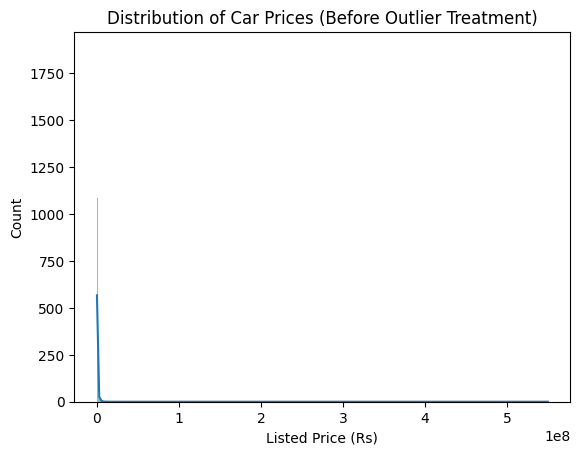

In [111]:
sns.histplot(df['listed_price'], kde=True)
plt.title('Distribution of Car Prices (Before Outlier Treatment)')
plt.xlabel('Listed Price (Rs)')
plt.ylabel('Count')
plt.show()

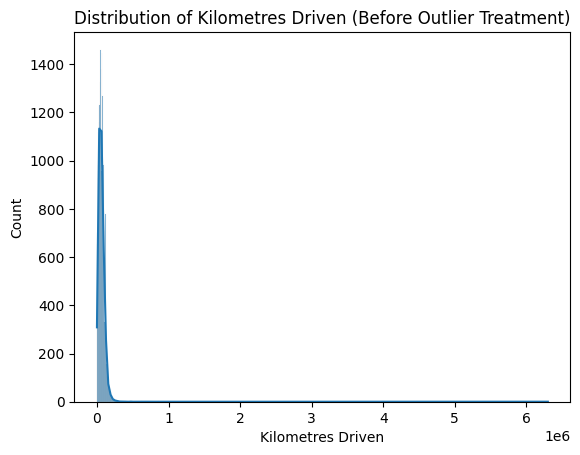

In [112]:
sns.histplot(df['km'], kde=True)
plt.title('Distribution of Kilometres Driven (Before Outlier Treatment)')
plt.xlabel('Kilometres Driven')
plt.ylabel('Count')
plt.show()

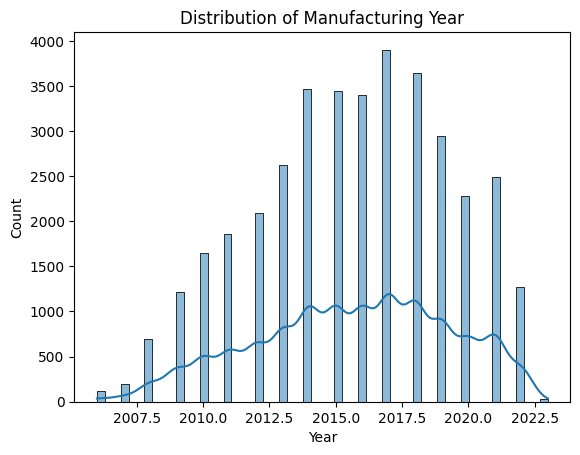

In [113]:
sns.histplot(df['myear'], kde=True)
plt.title('Distribution of Manufacturing Year')
plt.xlabel('Year')
plt.ylabel('Count')
plt.show()

In [114]:
# Price
q1 = df['listed_price'].quantile(0.25)
q3 = df['listed_price'].quantile(0.75)
iqr = q3 - q1
price_lower = q1 - 1.5 * iqr
price_upper = q3 + 1.5 * iqr
print("Price bounds:", price_lower, price_upper)
df['listed_price'] = df['listed_price'].clip(price_lower, price_upper)

Price bounds: -488500.0 1667500.0


In [115]:
# Km
q1 = df['km'].quantile(0.25)
q3 = df['km'].quantile(0.75)
iqr = q3 - q1
km_lower = q1 - 1.5 * iqr
km_upper = q3 + 1.5 * iqr
print("Km bounds:", km_lower, km_upper)
df['km'] = df['km'].clip(km_lower, km_upper)

Km bounds: -45505.75 160244.25


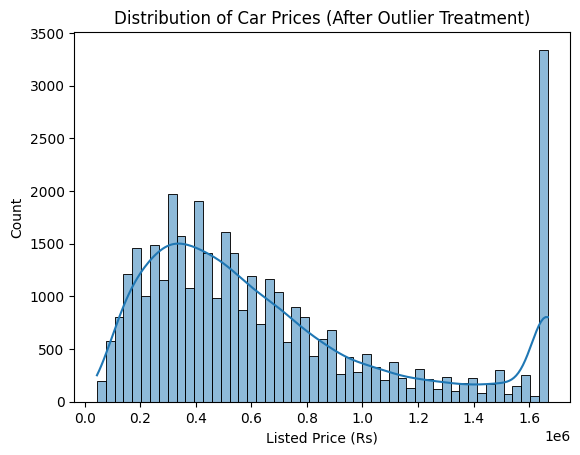

In [116]:
sns.histplot(df['listed_price'], kde=True)
plt.title('Distribution of Car Prices (After Outlier Treatment)')
plt.xlabel('Listed Price (Rs)')
plt.ylabel('Count')
plt.show()

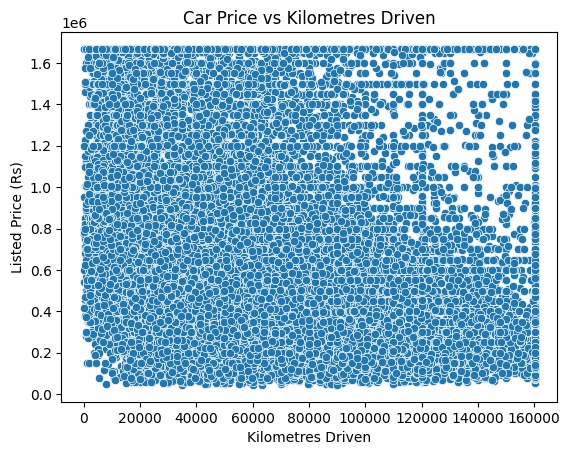

In [117]:
sns.scatterplot(x='km', y='listed_price', data=df)
plt.title('Car Price vs Kilometres Driven')
plt.xlabel('Kilometres Driven')
plt.ylabel('Listed Price (Rs)')
plt.show()

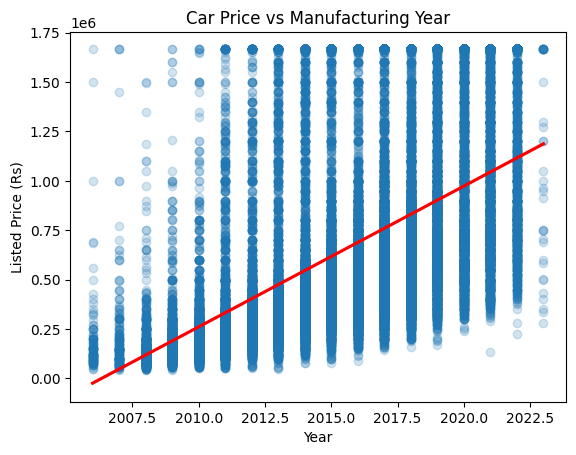

In [118]:
sns.regplot(x='myear', y='listed_price', data=df,
            scatter_kws={'alpha': 0.2}, line_kws={'color': 'red'})
plt.title('Car Price vs Manufacturing Year')
plt.xlabel('Year')
plt.ylabel('Listed Price (Rs)')
plt.show()

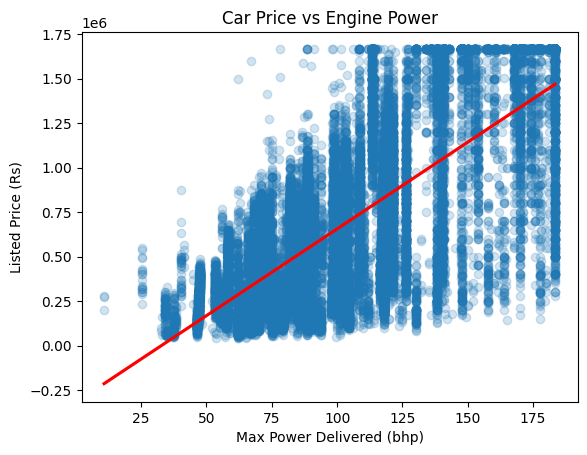

In [119]:
sns.regplot(x='Max Power Delivered', y='listed_price', data=df,
            scatter_kws={'alpha': 0.2}, line_kws={'color': 'red'})
plt.title('Car Price vs Engine Power')
plt.xlabel('Max Power Delivered (bhp)')
plt.ylabel('Listed Price (Rs)')
plt.show()

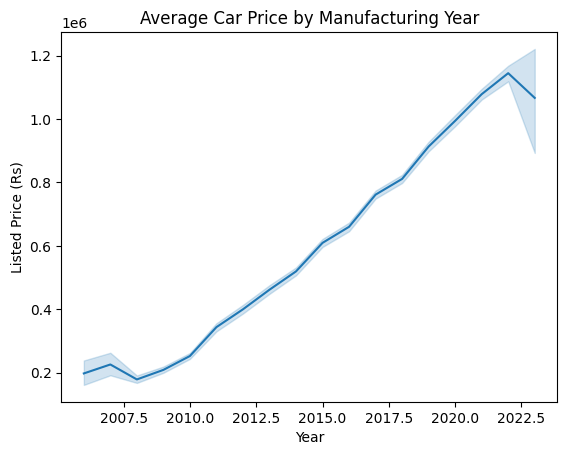

In [120]:
sns.lineplot(x='myear', y='listed_price', data=df)
plt.title('Average Car Price by Manufacturing Year')
plt.xlabel('Year')
plt.ylabel('Listed Price (Rs)')
plt.show()